<div style="border: solid green 2px; padding: 20px">

  <b>Overall Summary of the Project – Iteration 1</b><br><br>
  Hello Tom, congratulations on submitting your project!<br>

  My name is <b>Victor Camargo</b> 
  (<a href="https://hub.tripleten.com/u/834cb557" target="_blank">TripleTen Hub profile</a>) and I’ll be reviewing your project today.<br>

  <i>You can find my detailed feedback throughout the notebook, starting with comments labeled 
  <b>Reviewer’s comment – Iteration 1</b>.</i><br>

  <b>What you did well:</b><br>
  ✅ You verified the rougher recovery formula numerically and confirmed the dataset values match your calculation, and you carefully identified and excluded features that would cause leakage when building the model.<br>

  <b>Required fixes (only if red issues exist):</b><br>
  ⛔️ None. No unresolved red issues were found in this submission.<br>

  <b>Project Status:</b><br>
  <div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
    <b>Approved</b>
  </div>

  <hr><b>Legend:</b><br>

  <div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  Strong, correct solutions or good practices worth reusing.
  </div>

  <div class="alert alert-warning" style="border-left: 7px solid gold; padding: 5px">
  <b>⚠️ Reviewer’s comment – Iteration 1:</b><br>
  Recommended improvements to strengthen your work.
  </div>

  <div class="alert alert-danger" style="border-left: 7px solid red; padding: 5px">
  <b>⛔️ Reviewer’s comment – Iteration 1:</b><br>
  Required fixes. The project cannot be approved until these are addressed.
  </div>

  <div class="alert alert-info" style="border-left: 7px solid blue; padding: 5px">
  <b>Student’s Comment</b><br>
  You may add your own notes or explanations in a <b>Markdown cell</b> using:<br>
  <code>&lt;div class="alert alert-info" style="border-left: 7px solid blue"&gt;&lt;b&gt;Student’s Comment&lt;/b&gt;&lt;/div&gt;</code>
  </div>

  <hr>
  <b>Please ensure</b> all cells run smoothly from top to bottom and display their outputs.<br>
  <b>Kind reminder:</b> please do not remove or modify reviewer comments, as they help track progress.<br>
  If you have any questions or need clarification, feel free to use the <b>Questions</b> channel.

</div>

# Introduction

The goal of this project is to develop a machine learning model that predicts the efficiency of gold recovery at different stages of the gold ore processing pipeline. Specifically, the model must predict the recovery rates after the rougher stage and the final stage of processing. These predictions help evaluate how efficiently gold is extracted from ore during the industrial process.

The project involves working with real industrial data that includes information about ore composition, processing parameters, and metal concentrations at different stages of purification. The dataset contains training and test data, and the model must be evaluated using the sMAPE (Symmetric Mean Absolute Percentage Error) metric, which measures prediction accuracy relative to the true values.

The overall workflow will start with preprocessing the data making sure we can use it, EDA on the metal processing, handling missing values and anomalies, model training, model evaluation using cross-validation, and final testing on the test dataset. The final objective is to select the model that produces the lowest sMAPE error and therefore provides the most accurate predictions for gold recovery.


## Data Preperation

In [110]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error



### Load and Inspect

We will load in the data and then inpect the data for null values, duplications, and any other errors that may mess up our ability to do EDA, ML, and any other processes we may need to do. 

In [111]:
train= pd.read_csv('/datasets/gold_recovery_train.csv')
test= pd.read_csv('/datasets/gold_recovery_test.csv')
full= pd.read_csv('/datasets/gold_recovery_full.csv')

### Train info

In [112]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16860 entries, 0 to 16859
Data columns (total 87 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   date                                                16860 non-null  object 
 1   final.output.concentrate_ag                         16788 non-null  float64
 2   final.output.concentrate_pb                         16788 non-null  float64
 3   final.output.concentrate_sol                        16490 non-null  float64
 4   final.output.concentrate_au                         16789 non-null  float64
 5   final.output.recovery                               15339 non-null  float64
 6   final.output.tail_ag                                16794 non-null  float64
 7   final.output.tail_pb                                16677 non-null  float64
 8   final.output.tail_sol                               16715 non-null  float64


In [113]:
train.head()

,date,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,...,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
1,2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.462676,0.927452,16.634514,2.224930,...,13.992281,-505.503262,11.950531,-501.331529,10.039245,-500.169983,7.984757,-500.582168,13.998353,-599.787184
2,2016-01-15 02:00:00,6.055926,10.213995,5.383759,42.657501,68.116445,10.507046,0.953716,16.208849,2.257889,...,14.015015,-502.520901,11.912783,-501.133383,10.070913,-500.129135,8.013877,-500.517572,14.028663,-601.427363
3,2016-01-15 03:00:00,6.047977,9.977019,4.858634,42.689819,68.347543,10.422762,0.883763,16.532835,2.146849,...,14.036510,-500.857308,11.999550,-501.193686,9.970366,-499.201640,7.977324,-500.255908,14.005551,-599.996129
4,2016-01-15 04:00:00,6.148599,10.142511,4.939416,42.774141,66.927016,10.360302,0.792826,16.525686,2.055292,...,14.027298,-499.838632,11.953070,-501.053894,9.925709,-501.686727,7.894242,-500.356035,13.996647,-601.496691


In [114]:
train.describe()

,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
count,16788.000000,16788.000000,16490.000000,16789.000000,15339.000000,16794.000000,16677.000000,16715.000000,16794.000000,15553.000000,...,16731.000000,16747.000000,16768.000000,16767.000000,16775.000000,16775.000000,16775.000000,16776.000000,16757.000000,16775.000000
mean,4.716907,9.113559,8.301123,39.467217,67.213166,8.757048,2.360327,9.303932,2.687512,129.479789,...,19.101874,-494.164481,14.778164,-476.600082,15.779488,-500.230146,12.377241,-498.956257,18.429208,-521.801826
std,2.096718,3.389495,3.825760,13.917227,11.960446,3.634103,1.215576,4.263208,1.272757,45.386931,...,6.883163,84.803334,5.999149,89.381172,6.834703,76.983542,6.219989,82.146207,6.958294,77.170888
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000003,...,0.000000,-799.920713,0.000000,-800.021781,-0.423260,-799.741097,0.427084,-800.258209,0.024270,-810.473526
25%,3.971262,8.825748,6.939185,42.055722,62.625685,7.610544,1.641604,7.870275,2.172953,103.064021,...,14.508299,-500.837689,10.741388,-500.269182,10.977713,-500.530594,8.925586,-500.147603,13.977626,-501.080595
50%,4.869346,10.065316,8.557228,44.498874,67.644601,9.220393,2.453690,10.021968,2.781132,131.783108,...,19.986958,-499.778379,14.943933,-499.593286,15.998340,-499.784231,11.092839,-499.933330,18.034960,-500.109898
75%,5.821176,11.054809,10.289741,45.976222,72.824595,10.971110,3.192404,11.648573,3.416936,159.539839,...,24.983961,-494.648754,20.023751,-400.137948,20.000701,-496.531781,15.979467,-498.418000,24.984992,-499.565540
max,16.001945,17.031899,18.124851,53.611374,100.000000,19.552149,6.086532,22.317730,9.789625,251.999948,...,60.000000,-127.692333,28.003828,-71.472472,63.116298,-275.073125,39.846228,-120.190931,54.876806,-39.784927


In [115]:
train.shape

(16860, 87)

From doing a simple evaluation for the train data set, we can see that we can a ton of missing values, the date column is in the wrong format, and a lot of information in general. We will need to eventually drop and replace some of those values. Let's look at the test and full data as well, it would be expected they also have missing values.

### Test info

_

In [116]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5856 entries, 0 to 5855
Data columns (total 53 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date                                        5856 non-null   object 
 1   primary_cleaner.input.sulfate               5554 non-null   float64
 2   primary_cleaner.input.depressant            5572 non-null   float64
 3   primary_cleaner.input.feed_size             5856 non-null   float64
 4   primary_cleaner.input.xanthate              5690 non-null   float64
 5   primary_cleaner.state.floatbank8_a_air      5840 non-null   float64
 6   primary_cleaner.state.floatbank8_a_level    5840 non-null   float64
 7   primary_cleaner.state.floatbank8_b_air      5840 non-null   float64
 8   primary_cleaner.state.floatbank8_b_level    5840 non-null   float64
 9   primary_cleaner.state.floatbank8_c_air      5840 non-null   float64
 10  primary_clea

In [117]:
test.head()

,date,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-09-01 00:59:59,210.800909,14.993118,8.080000,1.005021,1398.981301,-500.225577,1399.144926,-499.919735,1400.102998,...,12.023554,-497.795834,8.016656,-501.289139,7.946562,-432.317850,4.872511,-500.037437,26.705889,-499.709414
1,2016-09-01 01:59:59,215.392455,14.987471,8.080000,0.990469,1398.777912,-500.057435,1398.055362,-499.778182,1396.151033,...,12.058140,-498.695773,8.130979,-499.634209,7.958270,-525.839648,4.878850,-500.162375,25.019940,-499.819438
2,2016-09-01 02:59:59,215.259946,12.884934,7.786667,0.996043,1398.493666,-500.868360,1398.860436,-499.764529,1398.075709,...,11.962366,-498.767484,8.096893,-500.827423,8.071056,-500.801673,4.905125,-499.828510,24.994862,-500.622559
3,2016-09-01 03:59:59,215.336236,12.006805,7.640000,0.863514,1399.618111,-498.863574,1397.440120,-499.211024,1400.129303,...,12.033091,-498.350935,8.074946,-499.474407,7.897085,-500.868509,4.931400,-499.963623,24.948919,-498.709987
4,2016-09-01 04:59:59,199.099327,10.682530,7.530000,0.805575,1401.268123,-500.808305,1398.128818,-499.504543,1402.172226,...,12.025367,-500.786497,8.054678,-500.397500,8.107890,-509.526725,4.957674,-500.360026,25.003331,-500.856333


In [118]:
test.describe()

,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
count,5554.000000,5572.000000,5856.000000,5690.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,...,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000
mean,170.515243,8.482873,7.264651,1.321420,1481.990241,-509.057796,1486.908670,-511.743956,1468.495216,-509.741212,...,15.636031,-516.266074,13.145702,-476.338907,12.308967,-512.208126,9.470986,-505.017827,16.678722,-512.351694
std,49.608602,3.353105,0.611526,0.693246,310.453166,61.339256,313.224286,67.139074,309.980748,62.671873,...,4.660835,62.756748,4.304086,105.549424,3.762827,58.864651,3.312471,68.785898,5.404514,69.919839
min,0.000103,0.000031,5.650000,0.000003,0.000000,-799.773788,0.000000,-800.029078,0.000000,-799.995127,...,0.000000,-799.798523,0.000000,-800.836914,-0.223393,-799.661076,0.528083,-800.220337,-0.079426,-809.859706
25%,143.340022,6.411500,6.885625,0.888769,1497.190681,-500.455211,1497.150234,-500.936639,1437.050321,-501.300441,...,12.057838,-501.054741,11.880119,-500.419113,10.123459,-500.879383,7.991208,-500.223089,13.012422,-500.833821
50%,176.103893,8.023252,7.259333,1.183362,1554.659783,-499.997402,1553.268084,-500.066588,1546.160672,-500.079537,...,17.001867,-500.160145,14.952102,-499.644328,12.062877,-500.047621,9.980774,-500.001338,16.007242,-500.041085
75%,207.240761,10.017725,7.650000,1.763797,1601.681656,-499.575313,1601.784707,-499.323361,1600.785573,-499.009545,...,18.030985,-499.441529,15.940011,-401.523664,15.017881,-499.297033,11.992176,-499.722835,21.009076,-499.395621
max,274.409626,40.024582,15.500000,5.433169,2212.432090,-57.195404,1975.147923,-142.527229,1715.053773,-150.937035,...,30.051797,-401.565212,31.269706,-6.506986,25.258848,-244.483566,14.090194,-126.463446,26.705889,-29.093593


In [119]:
test.shape

(5856, 53)

### Full info

_


In [120]:
full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22716 entries, 0 to 22715
Data columns (total 87 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   date                                                22716 non-null  object 
 1   final.output.concentrate_ag                         22627 non-null  float64
 2   final.output.concentrate_pb                         22629 non-null  float64
 3   final.output.concentrate_sol                        22331 non-null  float64
 4   final.output.concentrate_au                         22630 non-null  float64
 5   final.output.recovery                               20753 non-null  float64
 6   final.output.tail_ag                                22633 non-null  float64
 7   final.output.tail_pb                                22516 non-null  float64
 8   final.output.tail_sol                               22445 non-null  float64


In [121]:
full.head()

,date,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,...,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
1,2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.462676,0.927452,16.634514,2.224930,...,13.992281,-505.503262,11.950531,-501.331529,10.039245,-500.169983,7.984757,-500.582168,13.998353,-599.787184
2,2016-01-15 02:00:00,6.055926,10.213995,5.383759,42.657501,68.116445,10.507046,0.953716,16.208849,2.257889,...,14.015015,-502.520901,11.912783,-501.133383,10.070913,-500.129135,8.013877,-500.517572,14.028663,-601.427363
3,2016-01-15 03:00:00,6.047977,9.977019,4.858634,42.689819,68.347543,10.422762,0.883763,16.532835,2.146849,...,14.036510,-500.857308,11.999550,-501.193686,9.970366,-499.201640,7.977324,-500.255908,14.005551,-599.996129
4,2016-01-15 04:00:00,6.148599,10.142511,4.939416,42.774141,66.927016,10.360302,0.792826,16.525686,2.055292,...,14.027298,-499.838632,11.953070,-501.053894,9.925709,-501.686727,7.894242,-500.356035,13.996647,-601.496691


After examining the data for each of our datasets we con conclude that there are numerous missing values for each set. The dtype for the date is incorrect and we will need to convert it into datetime. Each of the datasets have different volumes of data and later that will need to be accounted for. We also need to check for duplicates, it would be wise to see if there are patterns in the missing data as well. 

### Conversion and Further Observation

In [122]:
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])
full['date'] = pd.to_datetime(full['date'])

train['date'].dtype

dtype('<M8[ns]')

In [123]:
train.isna().sum().sort_values(ascending=False).head(20)


rougher.output.recovery                     2573
rougher.output.tail_ag                      2250
rougher.output.tail_sol                     2249
rougher.output.tail_au                      2249
secondary_cleaner.output.tail_sol           1986
rougher.input.floatbank11_xanthate          1904
final.output.recovery                       1521
primary_cleaner.input.sulfate               1307
primary_cleaner.input.depressant            1262
rougher.calculation.au_pb_ratio             1242
rougher.input.floatbank10_sulfate           1044
primary_cleaner.input.xanthate               985
primary_cleaner.output.concentrate_sol       636
rougher.input.floatbank11_sulfate            623
rougher.state.floatbank10_e_air              603
rougher.input.feed_rate                      513
rougher.input.feed_size                      417
final.output.concentrate_sol                 370
secondary_cleaner.state.floatbank2_a_air     363
primary_cleaner.output.concentrate_pb        358
dtype: int64

In [124]:
train.duplicated().sum()

0

In [125]:
test.isna().sum().sort_values(ascending=False).head(20)

rougher.input.floatbank11_xanthate            353
primary_cleaner.input.sulfate                 302
primary_cleaner.input.depressant              284
rougher.input.floatbank10_sulfate             257
primary_cleaner.input.xanthate                166
rougher.input.floatbank10_xanthate            123
rougher.input.feed_sol                         67
rougher.input.floatbank11_sulfate              55
rougher.input.feed_rate                        40
secondary_cleaner.state.floatbank3_a_air       34
secondary_cleaner.state.floatbank2_b_air       23
rougher.input.feed_size                        22
secondary_cleaner.state.floatbank2_a_air       20
rougher.state.floatbank10_a_air                17
rougher.state.floatbank10_c_air                17
rougher.state.floatbank10_d_air                17
rougher.state.floatbank10_e_air                17
rougher.state.floatbank10_b_air                17
rougher.state.floatbank10_f_air                17
secondary_cleaner.state.floatbank3_a_level     16


In [126]:
test.duplicated().sum()

0

In [127]:
full.isna().sum().sort_values(ascending=False).head(20)

rougher.output.recovery                   3119
rougher.output.tail_ag                    2737
rougher.output.tail_au                    2736
rougher.output.tail_sol                   2736
rougher.input.floatbank11_xanthate        2257
secondary_cleaner.output.tail_sol         2215
final.output.recovery                     1963
rougher.calculation.au_pb_ratio           1627
primary_cleaner.input.sulfate             1609
primary_cleaner.input.depressant          1546
rougher.input.floatbank10_sulfate         1301
primary_cleaner.input.xanthate            1151
primary_cleaner.output.concentrate_sol     798
rougher.input.floatbank11_sulfate          678
rougher.state.floatbank10_e_air            620
rougher.input.feed_rate                    553
rougher.input.floatbank10_xanthate         469
primary_cleaner.output.concentrate_pb      448
rougher.input.feed_size                    439
final.output.concentrate_sol               385
dtype: int64

In [128]:
full.duplicated().sum()

0

Train and full both have simular missing value numbers, for example, each dataset's top value for missing values was recovery and so on. In test the data is analyzed different and therefore different missing values. Before we start cleaning the numbers up let's establish our what our features will be, what our equations will look like and then comparing using the mean absolute error to see if the calculations were run correctly to begin with by dropping the missing values for now. 

In [129]:
C = train['rougher.output.concentrate_au']# what the equation looks like before dropping
F = train['rougher.input.feed_au']
T = train['rougher.output.tail_au']

calculated_recovery = (C * (F - T)) / (F * (C - T)) * 100

In [130]:
valid_rows = train[['rougher.output.recovery',
                    'rougher.output.concentrate_au',
                    'rougher.input.feed_au',
                    'rougher.output.tail_au']].dropna()

C = valid_rows['rougher.output.concentrate_au']
F = valid_rows['rougher.input.feed_au']
T = valid_rows['rougher.output.tail_au']

calc_recovery = (C * (F - T)) / (F * (C - T)) * 100

mae = mean_absolute_error(valid_rows['rougher.output.recovery'], calc_recovery)

print("MAE:", mae)

MAE: 9.303415616264301e-15


<div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  Good job recalculating the rougher recovery and comparing it to the dataset value. The MAE you printed is effectively zero, which confirms the recovery formula was implemented correctly and the dataset values are consistent with that formula. This is an important validation step and you executed it clearly.
</div>

The recovery values were recalculated using the provided formula. The Mean Absolute Error between the calculated values and the dataset's rougher.output.recovery column was extremely small, confirming that the recovery values in the dataset were calculated correctly.

### Dealing with Leakage and Filling NAN

We need to inspect the data and make sure we are not using any features that would allow us to have the answers early. For example, anything that would have output or calculations were features made after observations were made. To do this we will find the difference between the twos' features. 

In [183]:
missing_columns = set(train.columns) - set(test.columns)
print(len(missing_columns))
missing_columns

34


{'final.output.concentrate_ag',
 'final.output.concentrate_au',
 'final.output.concentrate_pb',
 'final.output.concentrate_sol',
 'final.output.recovery',
 'final.output.tail_ag',
 'final.output.tail_au',
 'final.output.tail_pb',
 'final.output.tail_sol',
 'primary_cleaner.output.concentrate_ag',
 'primary_cleaner.output.concentrate_au',
 'primary_cleaner.output.concentrate_pb',
 'primary_cleaner.output.concentrate_sol',
 'primary_cleaner.output.tail_ag',
 'primary_cleaner.output.tail_au',
 'primary_cleaner.output.tail_pb',
 'primary_cleaner.output.tail_sol',
 'rougher.calculation.au_pb_ratio',
 'rougher.calculation.floatbank10_sulfate_to_au_feed',
 'rougher.calculation.floatbank11_sulfate_to_au_feed',
 'rougher.calculation.sulfate_to_au_concentrate',
 'rougher.output.concentrate_ag',
 'rougher.output.concentrate_au',
 'rougher.output.concentrate_pb',
 'rougher.output.concentrate_sol',
 'rougher.output.recovery',
 'rougher.output.tail_ag',
 'rougher.output.tail_au',
 'rougher.output.ta

<div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  Well done identifying the features that are present in the training data but absent from the test set and recognizing these are outputs and calculated features. Excluding those columns prevents leakage at prediction time and shows careful attention to what data is available when making real predictions.
</div>

The training dataset contains 34 features that are absent from the test dataset. Most of these features are related to (.output) parameters from different purification stages as well as (.calculation). These parameters are not available at prediction time because they are measured or calculated later in the production process. Including them in the model would cause data leakage. Therefore, only the features present in the test dataset will be used for training the model.

Now let's check the target columns.

In [131]:
train[['rougher.output.recovery', 'final.output.recovery']].isna().sum()

rougher.output.recovery    2573
final.output.recovery      1521
dtype: int64

The target variables contain missing values. Since machine learning models require known target values for training, rows with missing target values were removed. Imputing target values with the median, mean, or related features to help fill in would introduce artificial labels and reduce model reliability.

In [132]:
train = train.dropna(subset=['rougher.output.recovery', 'final.output.recovery'])
train.shape

(14149, 87)

Next we will create our features and target hopefully without to much leakage. 

In [133]:
features = test.columns.drop('date')

fea_train = train[features]
fea_test = test[features]

tar_train_rougher = train['rougher.output.recovery']
tar_train_final = train['final.output.recovery']

print('fea_train',fea_train.shape)
print('fea_test', fea_test.shape)
print('tar_train_rougher', tar_train_rougher.shape)
print('tar_train_final', tar_train_final.shape)

fea_train (14149, 52)
fea_test (5856, 52)
tar_train_rougher (14149,)
tar_train_final (14149,)


Even though we tried our best to not have leakage let's see how many we missed.

In [134]:
fea_train.isna().sum().sum()

1705

In [135]:
fea_test.isna().sum().sum()

2360

Because we do not want to leak information into the training data we need to use the median from fea_train and not fea_test. 

In [136]:
medians= fea_train.median()

In [137]:
fea_train = fea_train.fillna(medians)
fea_test = fea_test.fillna(medians)

<div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  Filling missing values using medians computed from the training set and then applying those medians to the test set is the correct approach to avoid leakage. Your choice of median is reasonable given the presence of outliers, and you applied it consistently.
</div>

In [138]:
fea_train.isna().sum().sum()

0

In [139]:
fea_test.isna().sum().sum()

0

We choose to use the median because it can handle outliers better than the mean, it wouldn't make sense to use the mode we aren't focusing on popularity or filling by proxy of a related column to avoid data leakage. Everything is now prepared for us to use in our EDA and then later to conduct the final results of the model. That will be the our next chapter.

## EDA

In [140]:
full[['rougher.input.feed_au',
      'rougher.output.concentrate_au',
      'final.output.concentrate_au']].describe()

,rougher.input.feed_au,rougher.output.concentrate_au,final.output.concentrate_au
count,22617.000000,22618.000000,22630.000000
mean,7.565838,17.879538,40.001172
std,3.026954,6.790112,13.398062
min,0.000000,0.000000,0.000000
25%,6.485009,17.928729,42.383721
50%,7.884832,20.003202,44.653436
75%,9.668064,21.564238,46.111999
max,14.093363,28.824507,53.611374


## 2.1  Analyze how metal concentrations change depending on the purification stage

From the project instructions:

“Take note of how the concentrations of metals (Au, Ag, Pb) change depending on the purification stage.”

This will be for Gold (Au)

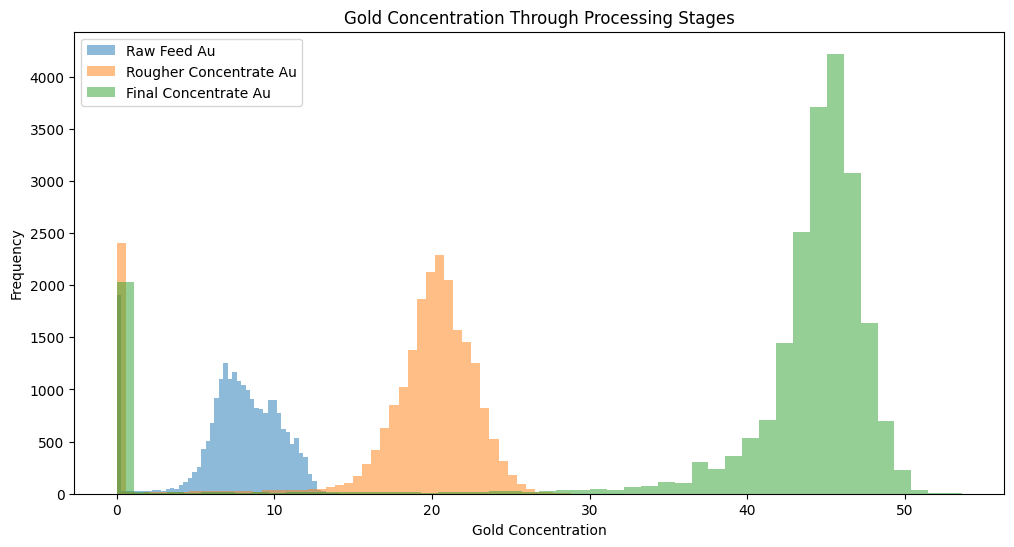

In [141]:
plt.figure(figsize=(12,6))

plt.hist(full['rougher.input.feed_au'], bins=50, alpha=0.5, label='Raw Feed Au')
plt.hist(full['rougher.output.concentrate_au'], bins=50, alpha=0.5, label='Rougher Concentrate Au')
plt.hist(full['final.output.concentrate_au'], bins=50, alpha=0.5, label='Final Concentrate Au')

plt.legend()
plt.title("Gold Concentration Through Processing Stages")
plt.xlabel("Gold Concentration")
plt.ylabel("Frequency")

plt.show()

The analysis of gold concentration across the purification stages shows a clear and consistent increase from the raw feed to the final concentrate. The average gold concentration rises from around 7.56 in the raw ore to 17.88 after the rougher stage, and to about 40.00 in the final concentrate. This confirms that the flotation and purification processes are effectively enriching the gold content at each stage.

The distribution plots also demonstrate a rightward shift in concentration values as the process progresses, which aligns with the expected behavior of a gold extraction pipeline.

However, small clusters of near-zero values were observed across all stages, particularly in the rougher concentrate. These values may indicate measurement errors, process interruptions, or sensor issues. These anomalies will be investigated further in a later step when analyzing total metal concentrations.

## Silver

In [142]:
full[['rougher.input.feed_ag',
      'rougher.output.concentrate_ag',
      'final.output.concentrate_ag']].describe()

,rougher.input.feed_ag,rougher.output.concentrate_ag,final.output.concentrate_ag
count,22618.000000,22618.000000,22627.000000
mean,8.065715,10.874484,4.781559
std,3.125250,4.377924,2.030128
min,0.000000,0.000000,0.000000
25%,6.944415,10.126646,4.018525
50%,8.302613,11.785127,4.953729
75%,10.135202,13.615299,5.862593
max,14.869652,24.480271,16.001945


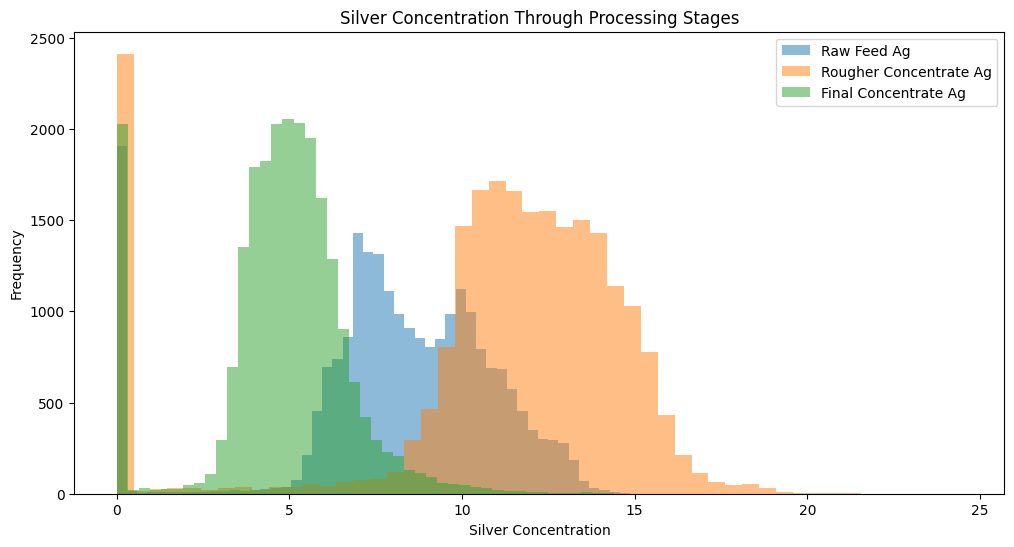

In [143]:
plt.figure(figsize=(12,6))

plt.hist(full['rougher.input.feed_ag'], bins=50, alpha=0.5, label='Raw Feed Ag')
plt.hist(full['rougher.output.concentrate_ag'], bins=50, alpha=0.5, label='Rougher Concentrate Ag')
plt.hist(full['final.output.concentrate_ag'], bins=50, alpha=0.5, label='Final Concentrate Ag')

plt.legend()
plt.title("Silver Concentration Through Processing Stages")
plt.xlabel("Silver Concentration")
plt.ylabel("Frequency")

plt.show()

The analysis of silver concentration shows a different trend compared to gold. The average concentration increases from approximately 8.07 in the raw feed to 10.87 after the rougher stage, indicating that silver is initially concentrated during flotation. However, in the final purification stage, the concentration drops significantly to about 4.78. Again we have a lot of zero values that indicate measurement errors, process interruptions, or sensor issues.

This suggests that while silver is recovered during the initial flotation process, it is subsequently removed during the cleaning stages as the process becomes more selective toward gold extraction. This behavior is consistent with the goal of maximizing gold purity in the final product.

Similar to gold, large clusters of near-zero values are present, which may indicate measurement errors or process irregularities. These will be further examined in the analysis of total metal concentrations

## Lead

In [144]:
full[['rougher.input.feed_pb',
      'rougher.output.concentrate_pb',
      'final.output.concentrate_pb']].describe()

,rougher.input.feed_pb,rougher.output.concentrate_pb,final.output.concentrate_pb
count,22472.000000,22618.000000,22629.000000
mean,3.305676,6.900646,9.095308
std,1.446905,2.806948,3.230797
min,0.000000,0.000000,0.000000
25%,2.658814,6.374692,8.750171
50%,3.432054,7.572855,9.914519
75%,4.204960,8.477358,10.929839
max,7.142594,18.394042,17.031899


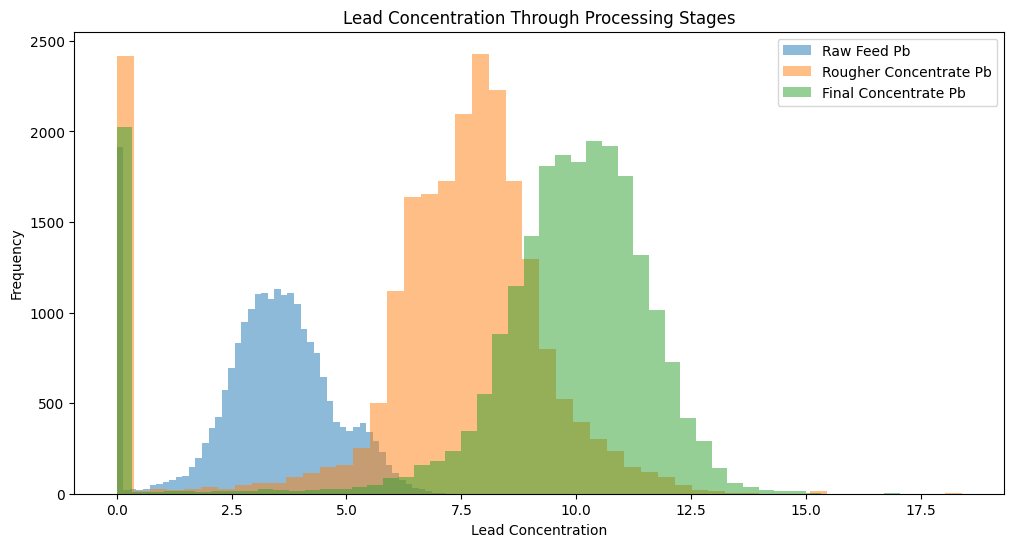

In [145]:
plt.figure(figsize=(12,6))

plt.hist(full['rougher.input.feed_pb'], bins=50, alpha=0.5, label='Raw Feed Pb')
plt.hist(full['rougher.output.concentrate_pb'], bins=50, alpha=0.5, label='Rougher Concentrate Pb')
plt.hist(full['final.output.concentrate_pb'], bins=50, alpha=0.5, label='Final Concentrate Pb')

plt.legend()
plt.title("Lead Concentration Through Processing Stages")
plt.xlabel("Lead Concentration")
plt.ylabel("Frequency")

plt.show()

The analysis of lead concentration shows a steady increase across all stages of the purification process, rising from approximately 3.31 in the raw feed to 6.90 after the rougher stage, and reaching about 9.10 in the final concentrate. This indicates that lead is progressively concentrated throughout the process.

However, compared to gold, the increase is less pronounced, and the distributions of lead concentration across stages show greater overlap. This suggests that while lead is enriched during processing, it is not as selectively targeted as gold.

Additionally, noticeable clusters of near-zero values are present, similar to those observed for silver. These may indicate measurement errors or process irregularities and will be further examined in the analysis of total metal concentrations.

## Comparing Train and Test

Feed Particle Size Distribution

Instruction:

“Compare the feed particle size distributions in the training set and in the test set.”

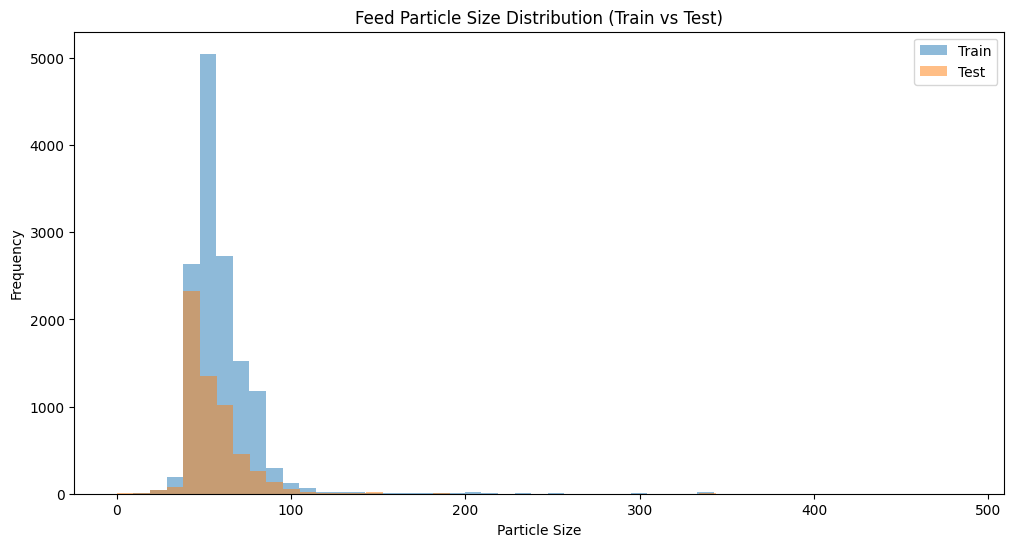

In [146]:
plt.figure(figsize=(12,6))

plt.hist(train['rougher.input.feed_size'], bins=50, alpha=0.5, label='Train')
plt.hist(test['rougher.input.feed_size'], bins=50, alpha=0.5, label='Test')

plt.legend()
plt.title("Feed Particle Size Distribution (Train vs Test)")
plt.xlabel("Particle Size")
plt.ylabel("Frequency")

plt.show()

The distributions of feed particle size in the training and test datasets are generally similar in shape, with both displaying a right skewed distribution and a long tail toward larger particle sizes. Although the training dataset shows higher frequencies and a slightly higher median value, this is expected due to differences in dataset size.

The key observation is that the distributions overlap significantly, indicating that both datasets are drawn from a similar pool of process. Therefore, the model trained on the training dataset should generalize well to the test dataset, and the evaluation results can be considered reliable.

## Total Metal Concentration Analysis

With a closer look at the data we can try to finally remove the NaN values. The total concentration of metals (gold, silver, and lead) is analyzed at different stages of the purification process. Since these metals represent the primary valuable components of the ore, their combined concentration provides insight into the overall effectiveness of the extraction and purification process.

Additionally, analyzing total concentrations helps identify abnormal or physically unrealistic values, such as near-zero totals, which may indicate measurement errors or missing data. To analyze the overall metal content, the total concentration was calculated as the sum of gold (Au), silver (Ag), and lead (Pb) at each stage of the process.

In [147]:
full['total_feed'] = (
    full['rougher.input.feed_au'] +
    full['rougher.input.feed_ag'] +
    full['rougher.input.feed_pb']
)

full['total_rougher'] = (
    full['rougher.output.concentrate_au'] +
    full['rougher.output.concentrate_ag'] +
    full['rougher.output.concentrate_pb']
)

full['total_final'] = (
    full['final.output.concentrate_au'] +
    full['final.output.concentrate_ag'] +
    full['final.output.concentrate_pb']
)

With everything together we can look at what the entire data will look like for each stage. 

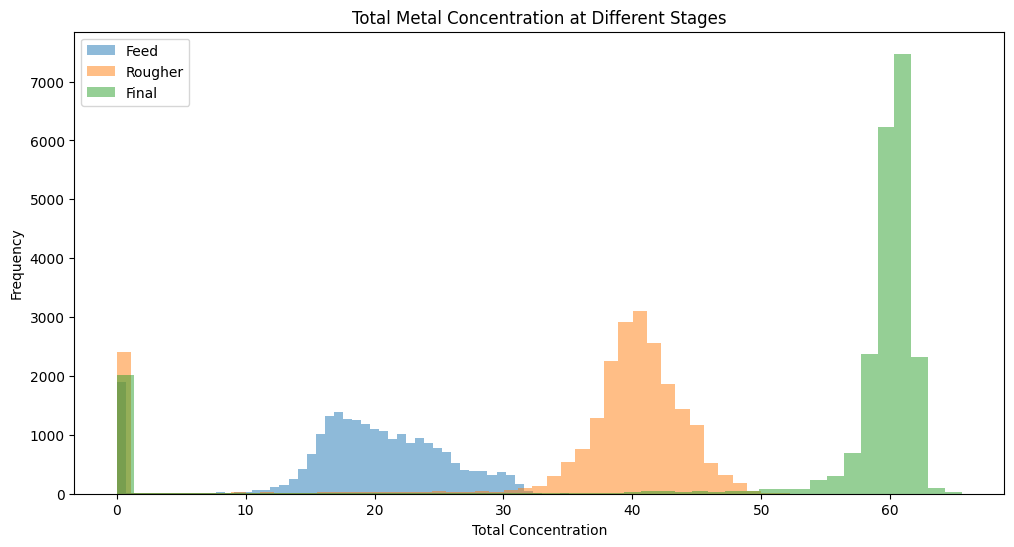

In [148]:
plt.figure(figsize=(12,6))

plt.hist(full['total_feed'], bins=50, alpha=0.5, label='Feed')
plt.hist(full['total_rougher'], bins=50, alpha=0.5, label='Rougher')
plt.hist(full['total_final'], bins=50, alpha=0.5, label='Final')

plt.legend()
plt.title("Total Metal Concentration at Different Stages")
plt.xlabel("Total Concentration")
plt.ylabel("Frequency")

plt.show()

Histograms were plotted to visualize the distribution of total metal concentration at each stage. The results show a clear progression. The raw feed has the lowest total concentration and the widest distribution, reflecting the variability of unprocessed ore. The rougher concentrate shows an increase in total concentration and a narrower distribution, indicating that valuable metals are being concentrated. The final concentrate has the highest total concentration and the most compact distribution, demonstrating the effectiveness of the purification process. This pattern confirms that the process is functioning as expected, progressively enriching the valuable metal content. Even though the overall consistency of the distributions, clusters of near-zero total concentration values were observed at all stages. Since total concentration is the sum of multiple metal components, values close to zero are unrealistic and suggest issues such as measurement errors, sensor failures, or incomplete data recording.

These issues do not represent valid process conditions and can negatively impact model performance if not addressed.

To improve data quality, rows with zero or near-zero total metal concentration were removed. For the training dataset, filtering was applied using total concentrations at all available stages (feed, rougher, and final).

For the test dataset, filtering was applied using only the raw feed total concentration, since later-stage outputs are not available at prediction time.

Removing these invalid observations ensures that the model is trained on realistic data and reduces the influence of noise and measurement errors.

In [149]:
# Create totals for train
train['total_feed'] = (
    train['rougher.input.feed_au'] +
    train['rougher.input.feed_ag'] +
    train['rougher.input.feed_pb']
)

train['total_rougher'] = (
    train['rougher.output.concentrate_au'] +
    train['rougher.output.concentrate_ag'] +
    train['rougher.output.concentrate_pb']
)

train['total_final'] = (
    train['final.output.concentrate_au'] +
    train['final.output.concentrate_ag'] +
    train['final.output.concentrate_pb']
)

# Filter
train = train[
    (train['total_feed'] > 0) &
    (train['total_rougher'] > 0) &
    (train['total_final'] > 0)
]

In [150]:
test['total_feed'] = (
    test['rougher.input.feed_au'] +
    test['rougher.input.feed_ag'] +
    test['rougher.input.feed_pb']
)

test = test[
    (test['total_feed'] > 0)
]

In [151]:
train = train.drop(columns=['total_feed', 'total_rougher', 'total_final'])
test = test.drop(columns=['total_feed'])

<div class="alert alert-warning" style="border-left: 7px solid gold; padding: 5px">
  <b>⚠️ Reviewer’s comment – Iteration 1:</b><br>
  Filtering out rows with zero total metal concentration is justified and improves data quality. Please add brief logging or a printout showing how many rows were removed from the training set and from the test set as a result of this filtering. That information helps reproduce the preprocessing and assess how much data remains for modeling.
</div>

Total metal concentrations were calculated for each stage. Rows with zero total concentration were removed, as such values are physically impossible and likely represent measurement errors. The filtering was applied to the training dataset using all available stages, while the test dataset was filtered using only the features available at prediction time. Now that we have taken a look at the data and cleaned it, we need to build a model to predict the processing of gold. Then use sMAPE to evaluate the model to see how accurate it is. 

## Modeling and sMAPE
### Making sMAPE

We will start this by making the sMAPE equation into a definition. We are using sMAPE to evaluate our model’s performance, so we need to implement it before training and comparing models. sMAPE measures error relative to the magnitude of the actual and predicted values, which ensures that both large and small values are treated fairly. This is important because gold recovery represents the efficiency of the extraction process and can vary across a wide range. As a result, relative error provides a more meaningful assessment of model accuracy than absolute error.

In [152]:
def smape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    
    # Avoid division by zero
    mask = denominator != 0
    
    result = np.zeros_like(y_true, dtype=float)
    result[mask] = np.abs(y_true[mask] - y_pred[mask]) / denominator[mask]
    
    return np.mean(result) * 100

<div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  The sMAPE implementation is robust, including a safe guard for zero denominators, and it returns the metric in percentage form. Also having the final weighted sMAPE function available makes the final evaluation straightforward. Good implementation.
</div>

In [153]:
def final_smape(rougher_true, rougher_pred, final_true, final_pred):
    smape_rougher = smape(rougher_true, rougher_pred)
    smape_final = smape(final_true, final_pred)
    return 0.25 * smape_rougher + 0.75 * smape_final

In [154]:
from sklearn.metrics import make_scorer # using this so that sklearn can evaluate our model using our custom equation (sMAPE) outside of mse or r^2

def smape_scorer(y_true, y_pred):
    return smape(y_true, y_pred)

smape_metric = make_scorer(smape_scorer, greater_is_better=False)

We needed to make a custom sMAPE function to evaluate model performance. The last function helps sklearn use our equation when we evaluate our model later on. The  earlier functions can handle for division by zero to ensure numerical stability. A final weighted sMAPE metric was also made, combining rougher and final recovery predictions with weights of 25% and 75%, respectively, as we will need it to measure our models effectiveness. Next we will make the models and find which is the best.

### Making Models

First we will seperate the data with their common columns for test and train to avoid data leakage like before but we are preparing this data for the models so it will be slightly different. Create our target using new variables than before. Then fill in the data like we did before as we had established using the median is best.

In [155]:
common_columns = train.columns.intersection(test.columns).drop('date')# creates a new df where train and test have the same columns, dropping date values to avoid errors

x_train = train[common_columns]
x_test = test[common_columns]

y_train_rougher = train['rougher.output.recovery'] # using a new variable just to make sure nothing gets messed up in calculations
y_train_final = train['final.output.recovery']

x_train = x_train.fillna(x_train.median())
x_test = x_test.fillna(x_train.median())

With the data ready to use lets make a function that helps us evaluate each of our models at once. In this function it will predict using each method and split the data into sections and use in this case 4/5ths of the data to predict the last section. Then it will do this for each method, once it is ready to be returned it is put through our smape function to see which model works best with our data.

In [156]:
from sklearn.model_selection import cross_val_predict

def evaluate_model(model, X, y):
    predictions = cross_val_predict(model, X, y, cv=5)
    return smape(y, predictions)

In [157]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=123),
    "Random Forest": RandomForestRegressor(random_state=123, n_estimators=50)
}

for name, model in models.items():
    rougher_smape = evaluate_model(model, x_train, y_train_rougher)
    final_smape_val = evaluate_model(model, x_train, y_train_final)
    
    final_metric = 0.25 * rougher_smape + 0.75 * final_smape_val
    
    print(name)
    print("Rougher sMAPE:", rougher_smape)
    print("Final sMAPE:", final_smape_val)
    print("Final Weighted sMAPE:", final_metric)
    print()

Linear Regression
Rougher sMAPE: 7.129664631574238
Final sMAPE: 11.108458446863791
Final Weighted sMAPE: 10.113759993041402

Decision Tree
Rougher sMAPE: 9.221223107579547
Final sMAPE: 16.77054773774551
Final Weighted sMAPE: 14.883216580204019

Random Forest
Rougher sMAPE: 6.8731751476126295
Final sMAPE: 9.573585693775119
Final Weighted sMAPE: 8.898483057234497



<div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  You evaluated multiple models using cross validation and selected the Random Forest based on the lowest weighted sMAPE. The use of cross_val_predict to obtain out of fold predictions for scoring is appropriate and your comparison is clear. Good selection rationale.
</div>

Here we are looking for which has the lowest weighted sMAPE. The best one is the lowest because that model has the less prediction error relative to the actual values. So the higher the number the more error it has it its predictions. Here we are looking for which has the lowest weighted sMAPE. The best model is the one with the lowest score because that means it has the least prediction error relative to the actual values. The higher the number, the more error the model has in its predictions. After comparing all three models, Random Forest produced the lowest weighted sMAPE and was selected for final evaluation.

In [181]:
model_rougher = RandomForestRegressor(random_state=123, n_estimators=50)
model_final = RandomForestRegressor(random_state=123, n_estimators=50)

model_rougher.fit(x_train, y_train_rougher)
model_final.fit(x_train, y_train_final)

rougher_pred = model_rougher.predict(x_test)
final_pred = model_final.predict(x_test)

rougher_true = full.loc[test.index, 'rougher.output.recovery']
final_true = full.loc[test.index, 'final.output.recovery']

# Combine into one dataframe to drop NaNs safely
results_df = pd.DataFrame({
    'rougher_true': rougher_true,
    'rougher_pred': rougher_pred,
    'final_true': final_true,
    'final_pred': final_pred
})

# Drop rows with NaN values
results_df = results_df.dropna()

final_test_smape = (
    0.25 * smape(results_df['rougher_true'], results_df['rougher_pred']) +
    0.75 * smape(results_df['final_true'], results_df['final_pred'])
)

print("Final sMAPE on Test Set:", final_test_smape)

Final sMAPE on Test Set: 13.643609587863839


<div class="alert alert-warning" style="border-left: 7px solid gold; padding: 5px">
  <b>⚠️ Reviewer’s comment – Iteration 1:</b><br>
  The final weighted sMAPE on the test sample is reported and the evaluation used the available true values from the full dataset. To make the final evaluation fully transparent, please indicate how many test rows were included in the final score after dropping rows with missing true values. Also consider saving the predictions together with the corresponding timestamps so you can inspect systematic errors over time.
</div>

A final weighted sMAPE of ~13.64% means that on average, the model's predictions 
are off by about 13.6% relative to the actual gold recovery values. Given the 
noise and complexity of real industrial sensor data, this is a reasonable result.

# Conclusion

In this project, a machine learning model was developed to predict gold recovery efficiency during different stages of the gold ore processing pipeline. The project began with data preprocessing, where missing values were analyzed and handled appropriately, and the training and test datasets were aligned to ensure consistent features for model training and prediction.

Exploratory data analysis was conducted to study the distribution of gold, silver, and lead concentrations at different processing stages. The analysis showed that gold concentration increases significantly from the feed stage to the rougher stage and reaches its highest concentration in the final stage, which is expected in a successful purification process. Silver and lead showed different behavior patterns, with silver decreasing in the final stage and lead increasing gradually through the stages. Outliers and zero concentration clusters were identified and removed by filtering rows where total metal concentrations were zero, which helped improve data quality.

After data cleaning and feature preparation, several machine learning models were trained and evaluated, including Linear Regression, Decision Tree, and Random Forest. Model performance was evaluated using cross-validation and the sMAPE metric, which was chosen because it fairly measures prediction error for both small and large values. The final evaluation metric combined the rougher recovery sMAPE and final recovery sMAPE using the weighted formula provided in the project requirements.

Among the tested models, the Random Forest model produced the lowest final weighted sMAPE score, indicating the best predictive performance. The Random Forest model was then trained on the full training dataset and used to make predictions on the test dataset. The final model evaluation on the test data produced the final sMAPE score, demonstrating that the model is capable of reasonably accurate predictions of gold recovery efficiency.

Overall, this project demonstrated the full machine learning workflow, including data preprocessing, exploratory data analysis, feature engineering, model training, model evaluation, and final testing. The Random Forest model was selected as the best model for predicting gold recovery, and the results show that machine learning can be effectively used to model and predict industrial mineral processing efficiency.
